# Exploratory data analysis: quote conversion

**Question:** which quotes bind, and why? The analysis uses the modeling table from `processing/03_build_model_table.ipynb` plus the train-only call notes.

**Contents**
1. Data overview: size, target, missing values
2. Do the splits look alike? (adversarial validation)
3. Conversion over time
4. Categorical drivers: channel, state, carrier, coverage, bundling…
5. Numeric drivers: price, credit, follow-up, drivers, vehicles
6. Price competitiveness: is the *price relative to risk* what matters?
7. Interactions: channel × shopping × follow-up × price
8. Census (ZIP) features
9. Missing values vs. conversion
10. Redundancy: correlated features
11. Call-note text: why quotes didn't bind
12. Overall signal ranking + quick LightGBM check
13. Key takeaways

Analysis uses the **labeled rows** (train + valid, 29,496 quotes); holdout appears only in section 2. Charts are saved to `eda/figures/` for the presentation. Every rate chart shows a **95% confidence interval** and a reference line at the overall conversion rate.

In [1]:
import re
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt, lightgbm as lgb
from matplotlib.colors import LinearSegmentedColormap, TwoSlopeNorm
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import StratifiedKFold, KFold, cross_val_predict

df = pd.read_parquet('../data/processed/model_table.parquet')
notes = pd.read_parquet('../data/processed/call_notes.parquet')
lab = df[df.CONVERT_IND.notna()].copy()
y, BASE = lab.CONVERT_IND, lab.CONVERT_IND.mean()
NON_FEATS = ['POLICY_ID', 'SPLIT', 'CONVERT_IND', 'QUOTE_DT', 'ZIP_CD', 'ZIP3']
FEATS = df.columns.drop(NON_FEATS).tolist()
FIG = Path('figures'); FIG.mkdir(exist_ok=True)

# Chart style: light surface, recessive grid/axes, fixed categorical order, one blue for single-series charts
SURF, INK, INK2, MUTED, GRID, AXIS = '#fcfcfb', '#0b0b0b', '#52514e', '#898781', '#e1e0d9', '#c3c2b7'
SERIES = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#008300', '#6250d6', '#e34948']
BLUES = LinearSegmentedColormap.from_list('blues', ['#cde2fb', '#6da7ec', '#2a78d6', '#184f95', '#0d366b'])
DIVERGE = LinearSegmentedColormap.from_list('div', ['#e34948', '#f0efec', '#2a78d6'])
plt.rcParams.update({'figure.facecolor': SURF, 'axes.facecolor': SURF, 'savefig.facecolor': SURF, 'figure.dpi': 110,
    'axes.edgecolor': AXIS, 'axes.labelcolor': INK2, 'axes.titlecolor': INK, 'axes.titlesize': 11, 'axes.titleweight': 'bold',
    'axes.titlelocation': 'left', 'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': True, 'grid.color': GRID,
    'grid.linewidth': 1, 'axes.axisbelow': True, 'xtick.color': MUTED, 'ytick.color': MUTED, 'xtick.labelcolor': INK2,
    'ytick.labelcolor': INK2, 'font.size': 9, 'lines.linewidth': 2, 'legend.frameon': False, 'axes.prop_cycle': plt.cycler(color=SERIES)})
pct = plt.FuncFormatter(lambda v, _: f'{v:.0%}')
k = lambda n: f'{n/1000:.1f}K' if n >= 1000 else str(n)
def logx(ax):  # log x-axis with compact labels (1K, 10K) instead of overlapping 3×10³ ticks
    ax.set_xscale('log'); ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: k(int(v)) if v >= 1 else f'{v:g}')); ax.xaxis.set_minor_formatter(plt.NullFormatter())

def rates(x, target=None):
    """Conversion rate, count and 95% CI half-width per level of x (labeled rows)."""
    g = (y if target is None else target).groupby(x, observed=True).agg(['mean', 'size'])
    return g.assign(ci=1.96 * np.sqrt(g['mean'] * (1 - g['mean']) / g['size']))

def rate_bars(ax, x, title, order=None):
    """Horizontal bars of conversion rate by category, labeled with rate and n."""
    r = rates(x)
    r = r.reindex(order) if order is not None else r.sort_values('mean')
    pos = np.arange(len(r))
    ax.barh(pos, r['mean'], height=.6, color=SERIES[0], xerr=r.ci, error_kw=dict(ecolor=MUTED, lw=1, capsize=0))
    ax.set_yticks(pos, [f'{i}  (n={k(n)})' for i, n in zip(r.index, r['size'])])
    ax.axvline(BASE, color=MUTED, lw=1); ax.xaxis.set_major_formatter(pct); ax.grid(axis='y', visible=False)
    for p, v, c in zip(pos, r['mean'], r.ci): ax.text(v + c + .002, p, f'{v:.1%}', va='center', color=INK2, fontsize=8)
    ax.set_title(title); ax.set_xlim(0, (r['mean'] + r.ci).max() * 1.25)

def rate_curve(ax, x, title, q=10, xlabel=None):
    """Conversion rate across quantile bins of a numeric feature (x = bin median); exact values if few distinct."""
    b = x if x.nunique() <= 12 else pd.qcut(x, q, duplicates='drop')
    r = rates(b).join(x.groupby(b, observed=True).median().rename('mid'))
    ax.fill_between(r.mid, r['mean'] - r.ci, r['mean'] + r.ci, color=SERIES[0], alpha=.1, lw=0)
    ax.plot(r.mid, r['mean'], color=SERIES[0], marker='o', ms=4, mec=SURF, mew=2)
    ax.axhline(BASE, color=MUTED, lw=1); ax.yaxis.set_major_formatter(pct); ax.set_title(title); ax.set_xlabel(xlabel or x.name)

def grid(n, ncols=3, w=4.6, h=2.9):
    fig, axes = plt.subplots(-(-n // ncols), ncols, figsize=(w * ncols, h * -(-n // ncols)), squeeze=False)
    for ax in axes.flat[n:]: ax.remove()
    return fig, axes.flat

def save(fig, name):
    fig.tight_layout(); fig.savefig(FIG / f'{name}.png', bbox_inches='tight')

## 1. Data overview

In [2]:
print(f'{len(df):,} quotes × {len(FEATS)} candidate features | labeled: {len(lab):,} | conversion rate: {BASE:.2%}')
display(df.groupby('SPLIT', observed=True).agg(quotes=('POLICY_ID', 'size'), converted=('CONVERT_IND', 'sum'), rate=('CONVERT_IND', 'mean')))
miss = df[FEATS].isna().mean()
display(miss[miss > 0].sort_values(ascending=False).to_frame('share missing').style.format('{:.2%}'))
df[FEATS].dtypes.astype(str).value_counts().to_frame('n columns').T

36,871 quotes × 77 candidate features | labeled: 29,496 | conversion rate: 11.17%


,quotes,converted,rate
SPLIT,,,
holdout,7375,0.0,NaN
train,22122,2472.0,0.111744
valid,7374,824.0,0.111744


,share missing
ACS_MED_AGE,0.95%
ACS_OWNER_OCC_SHARE,0.95%
ACS_EDU_NO_HS,0.95%
ACS_COMMUTE_45PLUS,0.95%
ACS_COMMUTE_MEAN_MIN,0.95%
ACS_COMMUTE_WFH,0.95%
ACS_COMMUTE_WALK_BIKE,0.95%
ACS_COMMUTE_TRANSIT,0.95%
ACS_COMMUTE_CARPOOL,0.95%
ACS_COMMUTE_DROVE_ALONE,0.95%


,float64,int64,int8,category,int32,Int8
n columns,40,19,9,5,3,1


- About **1 in 9 quotes binds**. That's unbalanced, but not extreme: ~3,300 positive examples is plenty for gradient boosting, and AUC doesn't depend on the balance.
- Train and valid have the **same conversion rate to four decimal places**, which suggests a stratified random split.
- Missing values are small (≤ 2%) apart from the categorical `PRIOR_CARRIER_GRP` (10%, now a `"Missing"` level, so it doesn't appear in the table).

## 2. Do the splits look alike? (adversarial validation)
A classifier is trained to tell **holdout** quotes from **labeled** ones. An AUC near 0.5 means it can't, so CV on labeled data should predict holdout performance well. The quote-date range is also compared.

In [3]:
is_hold = df.SPLIT.eq('holdout').astype(int)
adv = cross_val_predict(lgb.LGBMClassifier(n_estimators=200, learning_rate=.05, verbose=-1), df[FEATS], is_hold,
                        cv=StratifiedKFold(5, shuffle=True, random_state=0), method='predict_proba')[:, 1]
print(f'adversarial AUC (holdout vs labeled): {roc_auc_score(is_hold, adv):.3f}')
df.groupby('SPLIT', observed=True).QUOTE_DT.agg(['min', 'max'])

adversarial AUC (holdout vs labeled): 0.502


,min,max
SPLIT,,
holdout,2015-01-02,2018-12-31
train,2015-01-02,2018-12-31
valid,2015-01-02,2018-12-31


**Findings**
- The adversarial AUC is **0.50**: the classifier can't tell holdout from labeled quotes, and all splits cover the same dates (2015-01-02 to 2018-12-31).
- **So stratified K-fold CV on train + valid is a reliable stand-in for the holdout score.** Time-based validation isn't needed.

## 3. Conversion over time

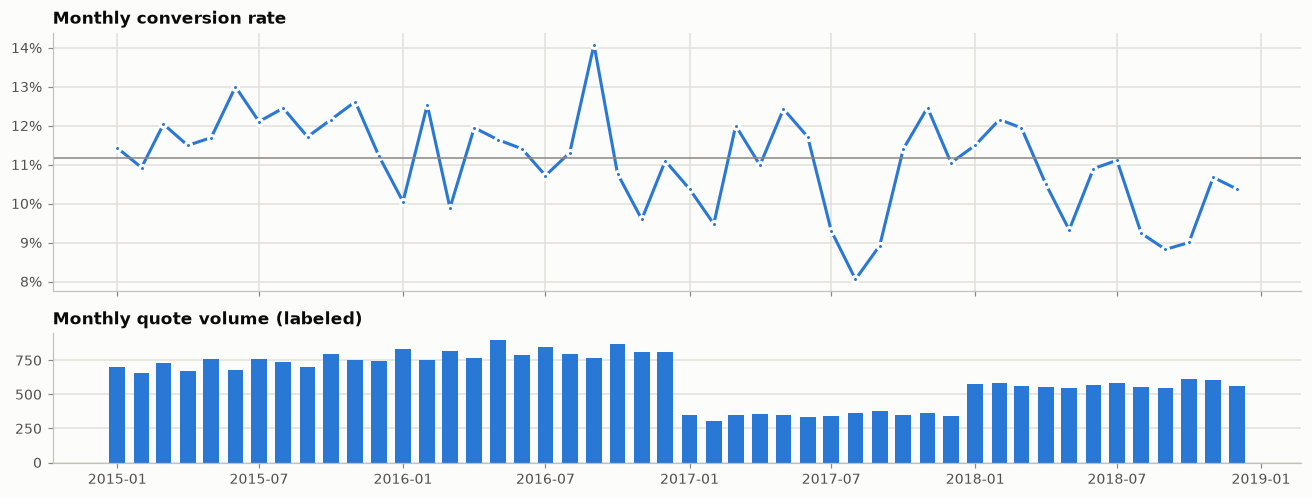

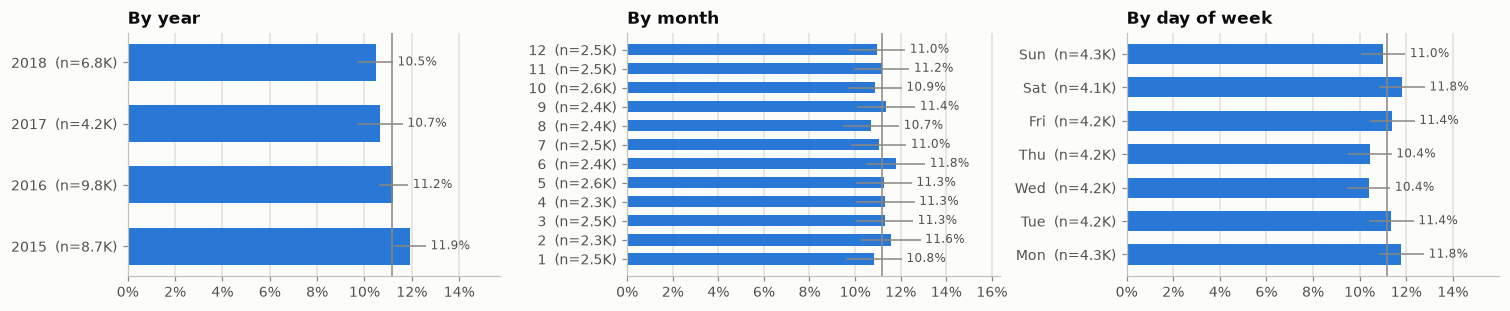

In [4]:
m = lab.set_index('QUOTE_DT').resample('MS')
fig, (a1, a2) = plt.subplots(2, 1, figsize=(12, 4.6), sharex=True, gridspec_kw={'height_ratios': [2, 1]})
r = m.CONVERT_IND.mean()
a1.plot(r.index, r, color=SERIES[0], marker='o', ms=4, mec=SURF, mew=2); a1.axhline(BASE, color=MUTED, lw=1)
a1.yaxis.set_major_formatter(pct); a1.set_title('Monthly conversion rate')
a2.bar(r.index, m.size(), width=20, color=SERIES[0]); a2.set_title('Monthly quote volume (labeled)'); a2.grid(axis='x', visible=False)
save(fig, '03_time_trend')

fig, ax = grid(3)
rate_bars(ax[0], lab.QUOTE_YEAR, 'By year', order=sorted(lab.QUOTE_YEAR.unique()))
rate_bars(ax[1], lab.QUOTE_MONTH, 'By month', order=range(1, 13))
rate_bars(ax[2], lab.QUOTE_DOW.map(dict(enumerate('Mon Tue Wed Thu Fri Sat Sun'.split()))), 'By day of week', order='Mon Tue Wed Thu Fri Sat Sun'.split())
save(fig, '03_time_parts')

**Findings**
- Conversion drifts down slightly by year: **11.9% (2015) → 10.5% (2018)**. Month-to-month swings between 8% and 14% are mostly noise.
- Monthly volume **halves in 2017** (~350/month vs ~800 in 2016). That's a quirk of how the dataset was sampled, not a business trend, so don't read anything into it.
- **No seasonality:** every month and weekday falls inside the confidence interval of the average.
- `QUOTE_YEAR` is safe to use as a feature here, because holdout spans the same years. It wouldn't carry over to future quotes, so present it as a trend, not a lever.

## 4. Categorical drivers
Conversion rate by level. Bars show the rate, whiskers the 95% CI, and the gray line the overall 11.2%.

,NUM_DRIVERS,STATE_CD,PRIOR_CARRIER_GRP,COV_PKG_TYPE,CAT_ZONE,TOTAL_NUM_VEH,VEH_N_ROWS,ACS_ZIP3_FILLED,DISCOUNT_IND,HOME_POLICY_IND,PRIMARY_PARKING,VEH_LUXURY_SHARE,DRV_TELEMATICS_ANY,NUM_OWNED_VEH,QUOTE_CHANNEL,NUM_LOANED_VEH,NUM_LEASED_VEH,PRIOR_CLAIMS_CNT,MULTI_QUOTE_IND
rate spread (pp),8.7,7.9,7.4,6.3,6.2,5.3,4.1,3.2,3.0,2.5,1.7,1.3,1.3,1.2,0.9,0.8,0.6,0.2,0.2


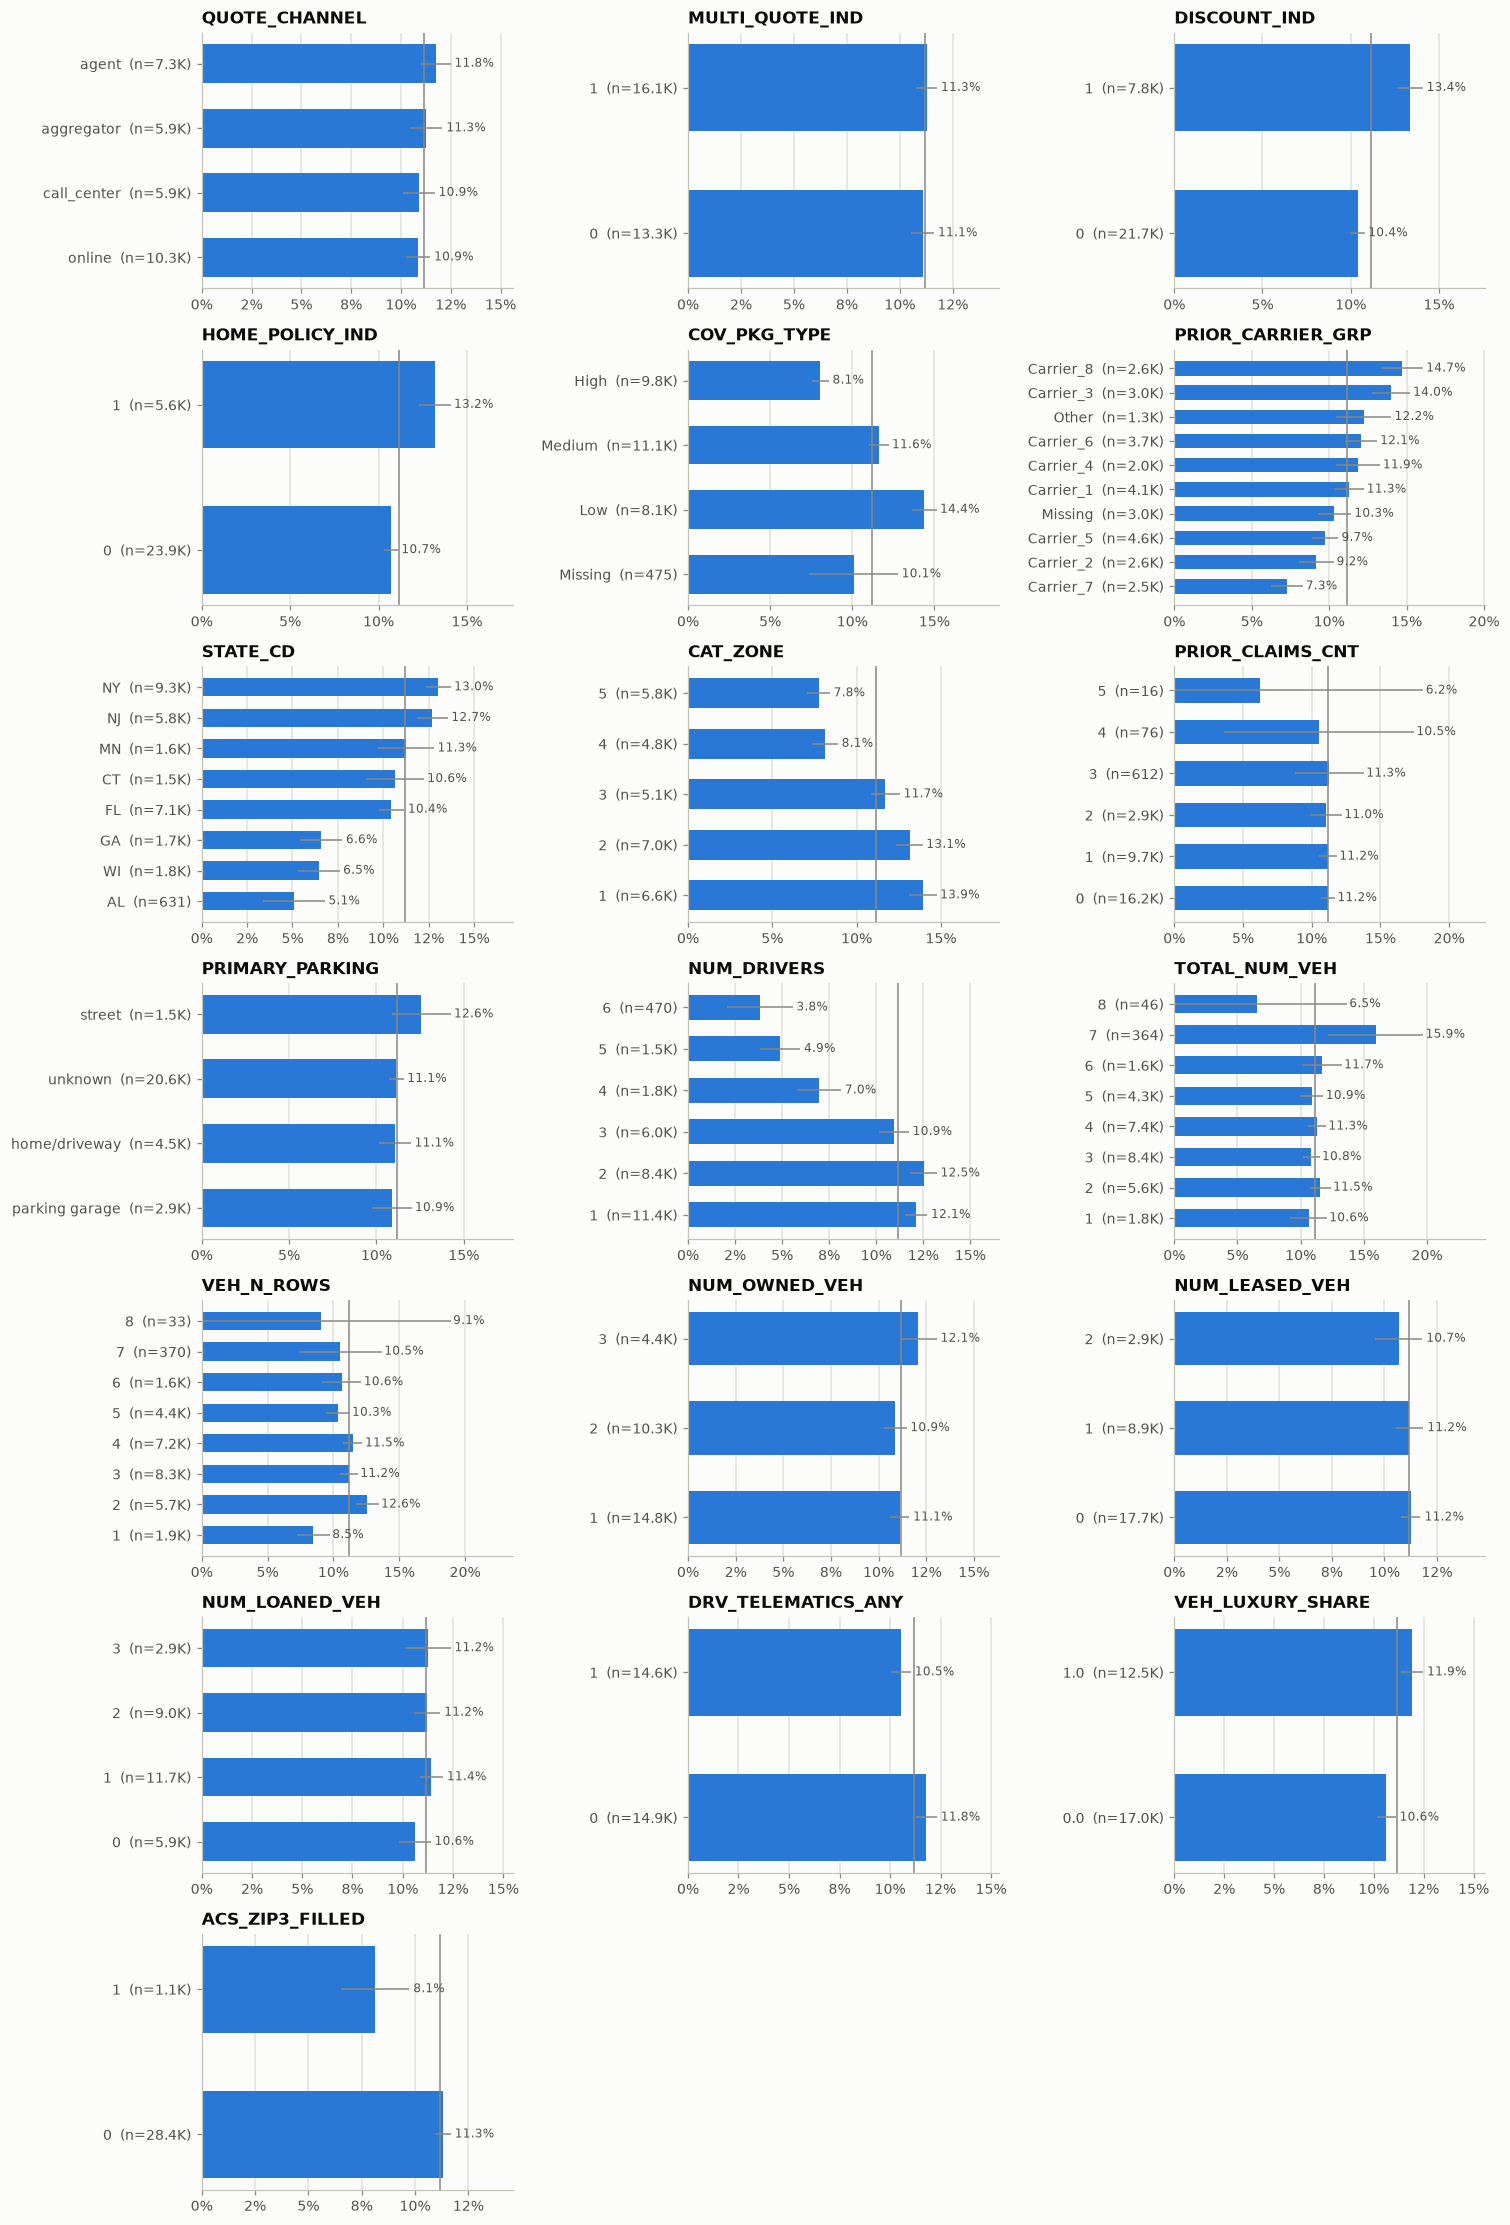

In [5]:
CATS = ['QUOTE_CHANNEL', 'MULTI_QUOTE_IND', 'DISCOUNT_IND', 'HOME_POLICY_IND', 'COV_PKG_TYPE', 'PRIOR_CARRIER_GRP',
        'STATE_CD', 'CAT_ZONE', 'PRIOR_CLAIMS_CNT', 'PRIMARY_PARKING', 'NUM_DRIVERS', 'TOTAL_NUM_VEH',
        'VEH_N_ROWS', 'NUM_OWNED_VEH', 'NUM_LEASED_VEH', 'NUM_LOANED_VEH', 'DRV_TELEMATICS_ANY', 'VEH_LUXURY_SHARE', 'ACS_ZIP3_FILLED']
ORDERED = {'COV_PKG_TYPE': ['Missing', 'Low', 'Medium', 'High']}
fig, ax = grid(len(CATS))
for a, c in zip(ax, CATS):
    natural = ORDERED.get(c, sorted(lab[c].dropna().unique()) if lab[c].dtype.kind in 'iuf' or str(lab[c].dtype) == 'Int8' else None)
    rate_bars(a, lab[c], c, order=natural)
save(fig, '04_categorical')

# Rank categoricals by spread: max − min level rate among levels with ≥ 200 quotes
spread = {c: (lambda r: r['mean'].max() - r['mean'].min())(rates(lab[c]).query('size >= 200')) for c in CATS}
pd.Series(spread).sort_values(ascending=False).to_frame('rate spread (pp)').mul(100).round(1).T

**Findings** (strongest separators first, by spread in percentage points)
- **Number of drivers (8.7 pp):** 1–2 drivers convert at ~12–12.5%, falling steadily to **3.8% at 6 drivers**.
- **State (7.9 pp):** NY/NJ ~13% vs GA/WI ~6.5% and AL 5.1%.
- **Prior carrier (7.4 pp):** customers leaving Carrier_8 / Carrier_3 convert at 14–15%, those leaving Carrier_7 at 7.3%. Some competitors are much easier to win from.
- **Coverage package (6.3 pp):** Low 14.4% > Medium 11.6% > High 8.1%.
- **CAT zone (6.2 pp):** zones 1–2 ~13–14% vs zones 4–5 ~8%.
- **Discount:** 13.4% vs 10.4%. **Home policy:** 13.2% vs 10.7%. Every home-policy holder also has a discount (see §7).
- **Luxury vehicles:** 11.9% vs 10.6%. In this data, a policy's vehicles are either all luxury or all non-luxury, so `VEH_LUXURY_SHARE` is effectively a yes/no flag.
- **Surprisingly flat:**
  - quote channel: 10.9–11.8%
  - multi-carrier shopping (`MULTI_QUOTE_IND`): 11.1% vs 11.3%
  - prior claims, parking, ownership counts, telematics

  On their own, the brief's "channel" and "shopping behavior" hypotheses get little support from the data.
- **Vehicle counts:** `TOTAL_NUM_VEH` (policy table) and `VEH_N_ROWS` (vehicle table) both lack a clean trend. Single-vehicle policies in the vehicle table convert less (8.5%).
- **`ACS_ZIP3_FILLED`:** 8.1%. These are small, rural ZIPs, which fits the density effect in §8.

## 5. Numeric drivers
Conversion rate across deciles. The x position is each decile's median value.

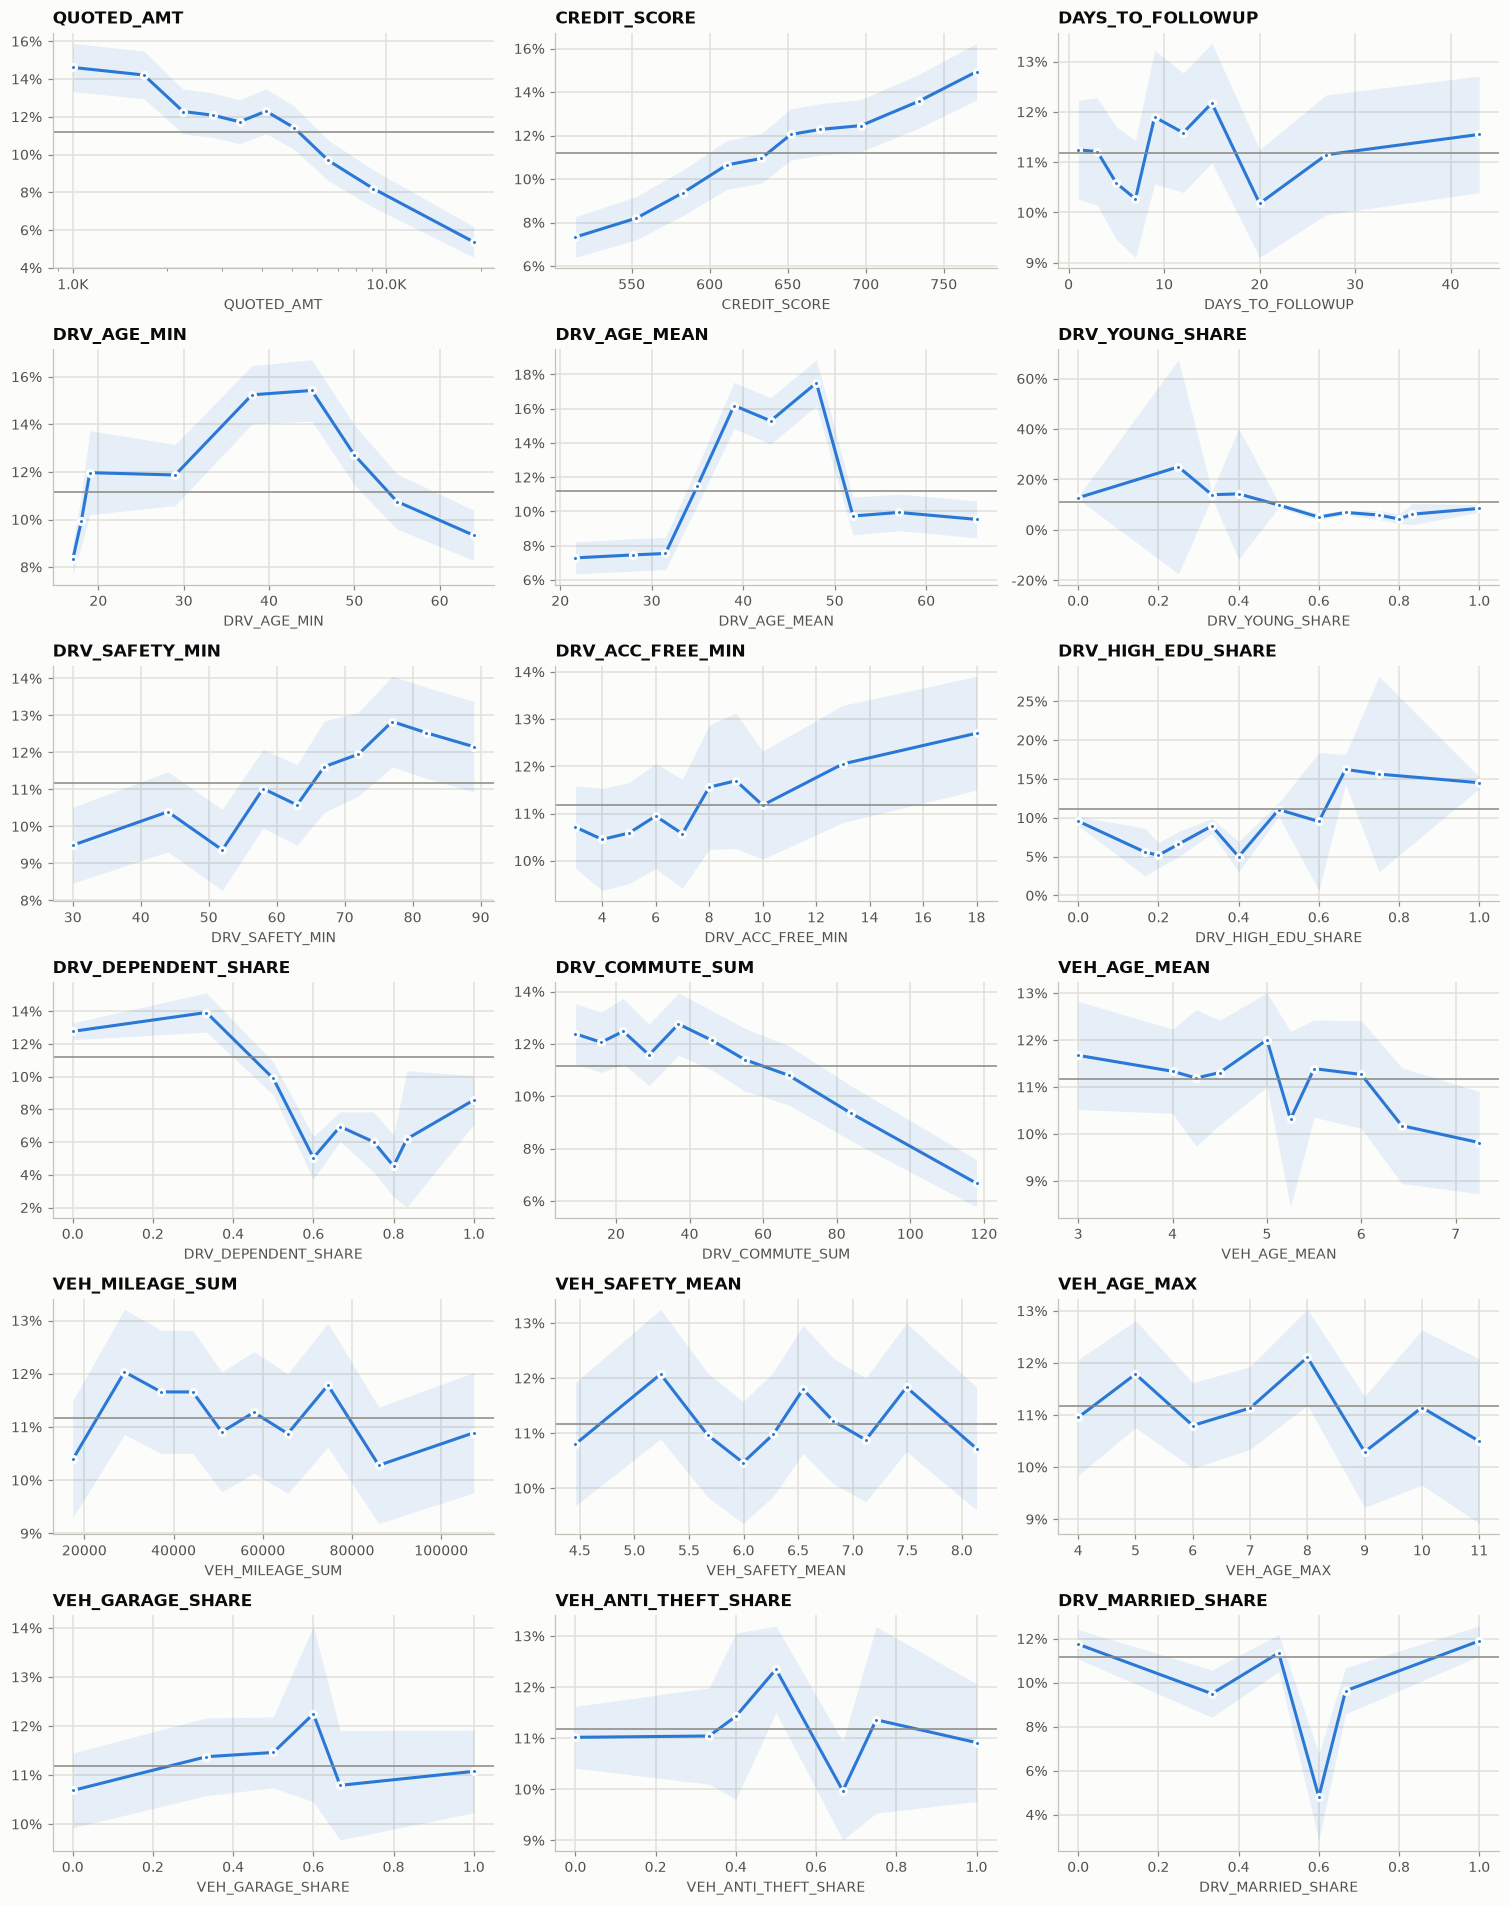

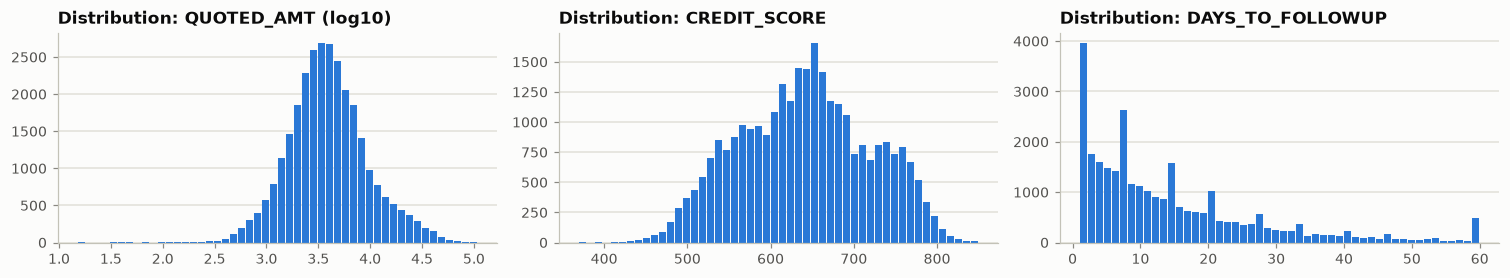

In [6]:
NUMS = ['QUOTED_AMT', 'CREDIT_SCORE', 'DAYS_TO_FOLLOWUP', 'DRV_AGE_MIN', 'DRV_AGE_MEAN', 'DRV_YOUNG_SHARE',
        'DRV_SAFETY_MIN', 'DRV_ACC_FREE_MIN', 'DRV_HIGH_EDU_SHARE', 'DRV_DEPENDENT_SHARE', 'DRV_COMMUTE_SUM', 'VEH_AGE_MEAN',
        'VEH_MILEAGE_SUM', 'VEH_SAFETY_MEAN', 'VEH_AGE_MAX', 'VEH_GARAGE_SHARE', 'VEH_ANTI_THEFT_SHARE', 'DRV_MARRIED_SHARE']
fig, ax = grid(len(NUMS))
for a, c in zip(ax, NUMS): rate_curve(a, lab[c], c)
logx(ax[0])
save(fig, '05_numeric')

fig, ax = grid(3, w=4.6, h=2.6)
for a, c, log in zip(ax, ['QUOTED_AMT', 'CREDIT_SCORE', 'DAYS_TO_FOLLOWUP'], [True, False, False]):
    v = np.log10(lab[c]) if log else lab[c]
    a.hist(v.dropna(), bins=50, color=SERIES[0], rwidth=.9); a.set_title(f'Distribution: {c}' + (' (log10)' if log else '')); a.grid(axis='x', visible=False)
save(fig, '05_distributions')

**Findings**
- **Credit score** is the cleanest driver: conversion rises steadily from **~7% at 520 to ~15% at 770**.
- **Quoted amount:** 14.6% in the cheapest decile vs **5.4% in the most expensive**.
- **Average driver age shows a sharp band:** policies averaging **35–50** convert at **15–17.5%**, vs 7–10% for younger or older households. Because the effect isn't monotone, single-feature AUC understates it (0.536), yet LightGBM ranks it #1 (§12).
- **High-education share above 0.5:** ~15–16% vs ~9%.
- **Total commute miles:** conversion falls from ~12% to ~7% above ~80 miles/day.
- **Share features:** the share features (young, dependent, married) have dips at values like 0.6, which only occur with 5 drivers. So they partly repeat the `NUM_DRIVERS` effect.
- **Days to follow-up: flat.** There's no evidence that faster follow-up converts better.
- **Vehicle features are within noise:** age, mileage, safety score, garage and anti-theft.

## 6. Price competitiveness
Raw price mixes two things: **how risky / large** the policy is (more vehicles, worse credit, more claims → higher price), and **how competitive** the quote is for that risk. The business question is about the second.

Two ways to isolate it, neither using the target:
- **Peer ratio:** quote ÷ median quote of the same state × coverage package × number of drivers.
- **Price residual:** a LightGBM regression predicts `log(QUOTED_AMT)` from the risk and policy features (out-of-fold, all splits). The residual is *log(actual) − log(expected)*: positive means priced above what similar risks are quoted.

They're compared with raw price by single-feature AUC. A clearly higher AUC for the residual would mean conversion responds to relative price, not absolute price.

price model R² (log scale): 0.746


,QUOTED_AMT,PRICE_PEER_RATIO,PRICE_RESID
single-feature AUC,0.571,0.541,0.523


,CREDIT_SCORE,STATE_CD,COV_PKG_TYPE,HOME_POLICY_IND,VEH_MILEAGE_MAX,VEH_SAFETY_MEAN,VEH_SAFETY_MIN,PRIOR_CARRIER_GRP
share of price-model gain,0.752,0.16,0.015,0.003,0.003,0.003,0.003,0.003


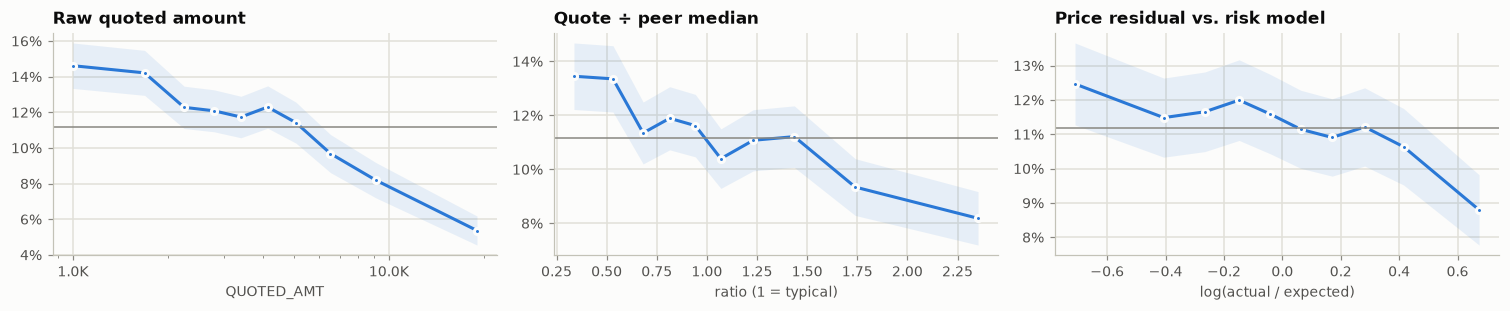

In [7]:
priced = df[df.QUOTED_AMT.notna()]
peer = priced.groupby(['STATE_CD', 'COV_PKG_TYPE', 'NUM_DRIVERS'], observed=True).QUOTED_AMT.transform('median')
df['PRICE_PEER_RATIO'] = priced.QUOTED_AMT / peer

RISK = [c for c in FEATS if not c.startswith(('QUOTED_AMT', 'QUOTE_', 'DAYS_TO', 'MULTI_QUOTE', 'DISCOUNT'))]  # what a rater would use
log_exp = cross_val_predict(lgb.LGBMRegressor(n_estimators=400, learning_rate=.05, verbose=-1), priced[RISK], np.log(priced.QUOTED_AMT),
                            cv=KFold(5, shuffle=True, random_state=0))
df['PRICE_RESID'] = pd.Series(np.log(priced.QUOTED_AMT) - log_exp, index=priced.index)
print(f'price model R² (log scale): {1 - df.PRICE_RESID.var() / np.log(priced.QUOTED_AMT).var():.3f}')
lab[['PRICE_PEER_RATIO', 'PRICE_RESID']] = df.loc[lab.index, ['PRICE_PEER_RATIO', 'PRICE_RESID']]

auc_dir = lambda t, s: (lambda a: max(a, 1 - a))(roc_auc_score(t[s.notna()], s.dropna()))  # direction-free AUC (flip if < 0.5)
auc1 = lambda s: auc_dir(y, s)
display(pd.Series({c: auc1(lab[c]) for c in ['QUOTED_AMT', 'PRICE_PEER_RATIO', 'PRICE_RESID']}).round(3).to_frame('single-feature AUC').T)

fig, ax = grid(3)
rate_curve(ax[0], lab.QUOTED_AMT, 'Raw quoted amount'); logx(ax[0])
rate_curve(ax[1], lab.PRICE_PEER_RATIO, 'Quote ÷ peer median', xlabel='ratio (1 = typical)')
rate_curve(ax[2], lab.PRICE_RESID, 'Price residual vs. risk model', xlabel='log(actual / expected)')
save(fig, '06_price_competitiveness')

# Which risk features drive the price itself (gain importance of the price model)?
pm = lgb.LGBMRegressor(n_estimators=400, learning_rate=.05, verbose=-1).fit(priced[RISK], np.log(priced.QUOTED_AMT))
pd.Series(pm.booster_.feature_importance('gain'), RISK).nlargest(8).div(pm.booster_.feature_importance('gain').sum()).round(3).to_frame('share of price-model gain').T

**Findings**
- **BlueShell's price is mostly credit score and state.** The risk model explains 75% of log-price variance, with ~75% of its gain from `CREDIT_SCORE` and ~16% from `STATE_CD`.
- **Conversion responds to absolute price, not price relative to risk.** Single-feature AUC is 0.571 for raw price, 0.541 for the peer ratio and 0.523 for the residual. The most over-priced fifth (by residual) still converts less (~9%), but the effect is weaker than raw price.
- Raw price works partly because it also carries the credit effect: high credit means both a lower price and a higher propensity to buy.
- Neither engineered price feature improves the LightGBM check (§12), so raw `QUOTED_AMT` is enough.

## 7. Interactions
Heatmaps of conversion rate, each cell labeled with rate and n. Color is **diverging around the overall 11.2%**: blue = converts better than average, red = worse, gray ≈ average. "—" marks an empty cell. These test whether the effects of channel, shopping behavior, follow-up speed and price stack up or depend on each other.

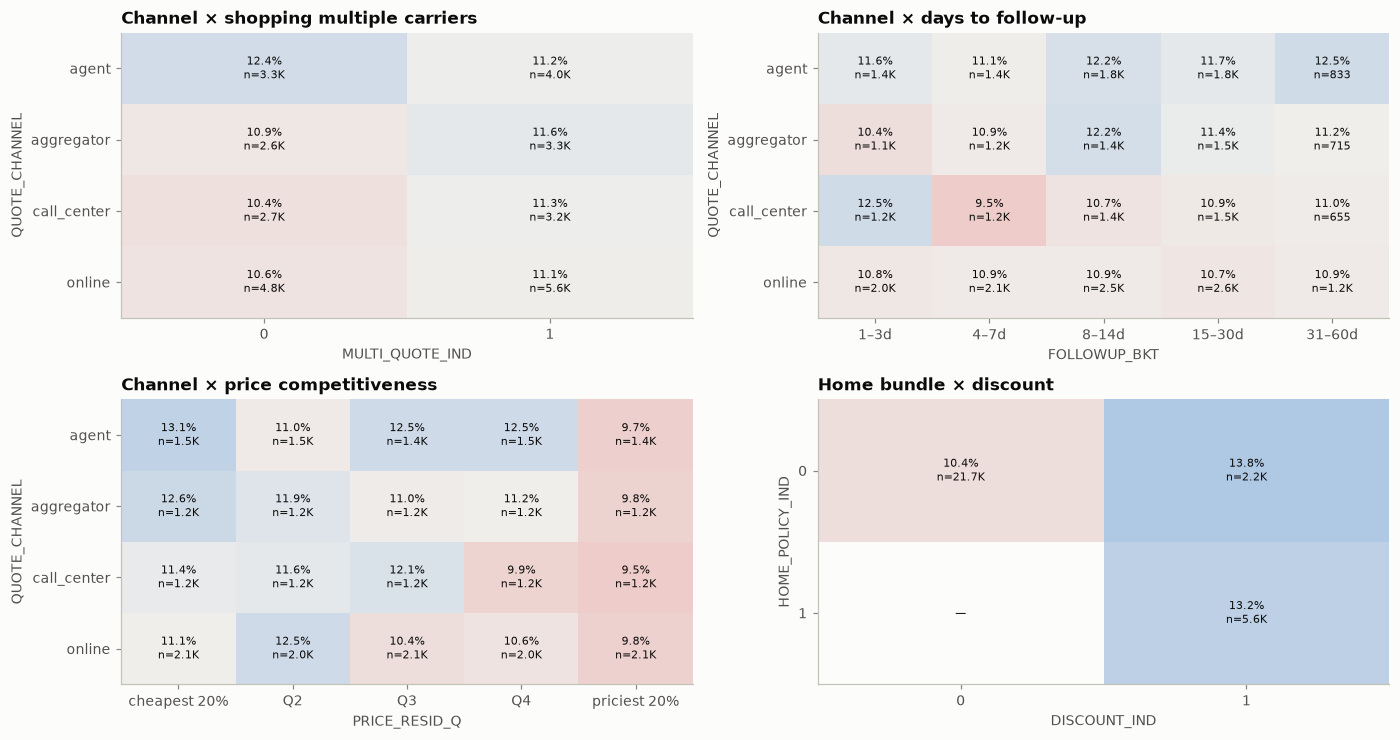

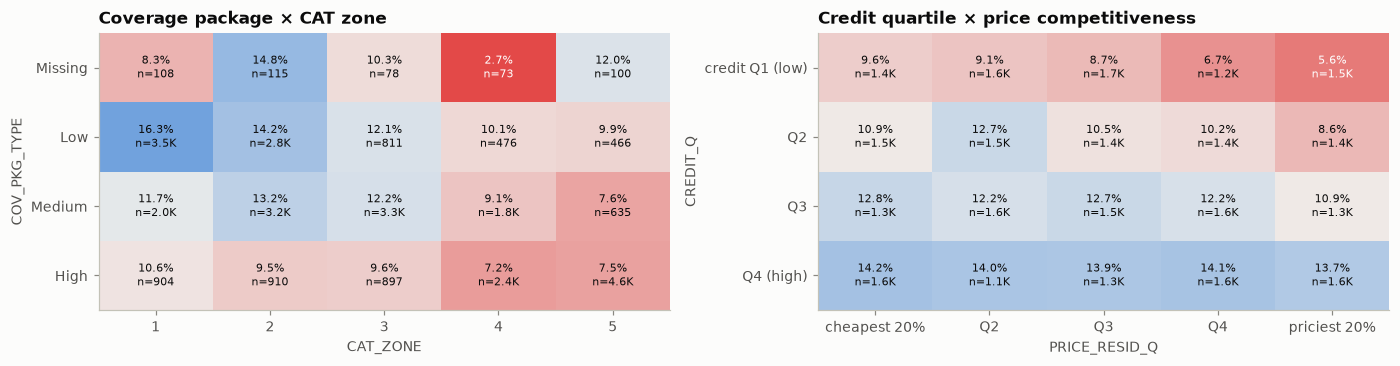

In [8]:
lab['FOLLOWUP_BKT'] = pd.cut(lab.DAYS_TO_FOLLOWUP, [0, 3, 7, 14, 30, 60], labels=['1–3d', '4–7d', '8–14d', '15–30d', '31–60d'])
lab['PRICE_RESID_Q'] = pd.qcut(lab.PRICE_RESID, 5, labels=['cheapest 20%', 'Q2', 'Q3', 'Q4', 'priciest 20%'])
lab['CREDIT_Q'] = pd.qcut(lab.CREDIT_SCORE, 4, labels=['credit Q1 (low)', 'Q2', 'Q3', 'Q4 (high)'])

def heat(ax, r, c, title):
    t = lab.pivot_table(index=r, columns=c, values='CONVERT_IND', aggfunc=['mean', 'size'], observed=True)
    rate, n = t['mean'], t['size']
    ax.imshow(rate, cmap=DIVERGE, norm=TwoSlopeNorm(BASE, BASE - .08, BASE + .08), aspect='auto')  # red = below overall rate, blue = above
    ax.set_xticks(range(rate.shape[1]), rate.columns, rotation=0); ax.set_yticks(range(rate.shape[0]), rate.index); ax.grid(False)
    for (i, j), v in np.ndenumerate(rate.values):
        ax.text(j, i, '—' if np.isnan(v) else f'{v:.1%}\nn={k(n.values[i, j])}', ha='center', va='center', fontsize=7.5,
                color='#ffffff' if abs(v - BASE) > .055 else INK)
    ax.set_title(title); ax.set_xlabel(c); ax.set_ylabel(r)

fig, ax = grid(4, ncols=2, w=6.4, h=3.4)
heat(ax[0], 'QUOTE_CHANNEL', 'MULTI_QUOTE_IND', 'Channel × shopping multiple carriers')
heat(ax[1], 'QUOTE_CHANNEL', 'FOLLOWUP_BKT', 'Channel × days to follow-up')
heat(ax[2], 'QUOTE_CHANNEL', 'PRICE_RESID_Q', 'Channel × price competitiveness')
heat(ax[3], 'HOME_POLICY_IND', 'DISCOUNT_IND', 'Home bundle × discount')
save(fig, '07_interactions')

fig, ax = grid(2, ncols=2, w=6.4, h=3.4)
heat(ax[0], 'COV_PKG_TYPE', 'CAT_ZONE', 'Coverage package × CAT zone')
heat(ax[1], 'CREDIT_Q', 'PRICE_RESID_Q', 'Credit quartile × price competitiveness')
save(fig, '07_interactions_2')

**Findings**
- **Channel interactions are weak.**
  - No channel × shopping or channel × follow-up cell is clearly different from average. Each cell has n ≈ 1–2K, so its CI is about ±1.7 pp.
  - The one standout, call center at 4–7 days (9.5%), is within the range you'd expect by chance across 20 cells.
- **The price penalty is the same in every channel:** the most over-priced fifth converts at ~9.5–9.8% everywhere.
- **The discount works on its own:**
  - Every `HOME_POLICY_IND = 1` quote also has `DISCOUNT_IND = 1`, so the bundle always comes with a discount.
  - Discounted quotes **without** a home policy (n = 2.2K) convert at 13.8%, so the discount itself matters, not only the bundle.
- **Coverage package and CAT zone add up:** Low package in zone 1 converts at **16.3%**, High package in zones 4–5 at **7.2–7.5%**.
- **Credit × price: low-credit customers are the price-sensitive ones.**
  - High-credit quotes convert at ~14% no matter how they're priced.
  - Low-credit quotes drop from 9.6% to **5.6%** going from the cheapest to the priciest fifth.
  - That is where a targeted discount could change outcomes.

## 8. Census (ZIP) features
Two questions: does the neighborhood matter, and **does it add anything beyond state**? Census features vary mostly *between* states (e.g. NY transit), so each feature also gets a **within-state AUC**: the AUC computed separately in each state, then averaged weighted by quote count. If within-state AUC drops to ~0.5, the feature is mostly a proxy for state.

,ACS_POP_DENSITY,ACS_COMMUTE_TRANSIT,ACS_COMMUTE_DROVE_ALONE,ACS_COMMUTE_MEAN_MIN,ACS_LAND_SQMI,ACS_COMMUTE_45PLUS,ACS_NO_VEH_SHARE,ACS_VEH_PER_HH,ACS_OWNER_OCC_SHARE,ACS_COMMUTE_WALK_BIKE,ACS_COMMUTE_CARPOOL,ACS_POPULATION,ACS_EDU_NO_HS,ACS_MED_HH_INCOME,ACS_COMMUTE_WFH,ACS_EDU_BACHELOR_PLUS,ACS_MED_AGE
overall AUC,0.557,0.556,0.547,0.546,0.544,0.544,0.542,0.539,0.529,0.529,0.527,0.520,0.513,0.509,0.508,0.506,0.504
within-state AUC,0.544,0.537,0.539,0.518,0.532,0.520,0.538,0.537,0.536,0.530,0.531,0.526,0.516,0.515,0.520,0.512,0.523


ACS_POP_DENSITY,sparse,Q2,Q3,dense
STATE_CD,,,,
AL,0.71,0.15,0.09,0.05
CT,0.38,0.22,0.25,0.15
FL,0.24,0.37,0.30,0.10
GA,0.31,0.33,0.26,0.09
MN,0.32,0.27,0.25,0.16
NJ,0.26,0.27,0.23,0.24
NY,0.17,0.14,0.25,0.45
WI,0.32,0.29,0.19,0.21


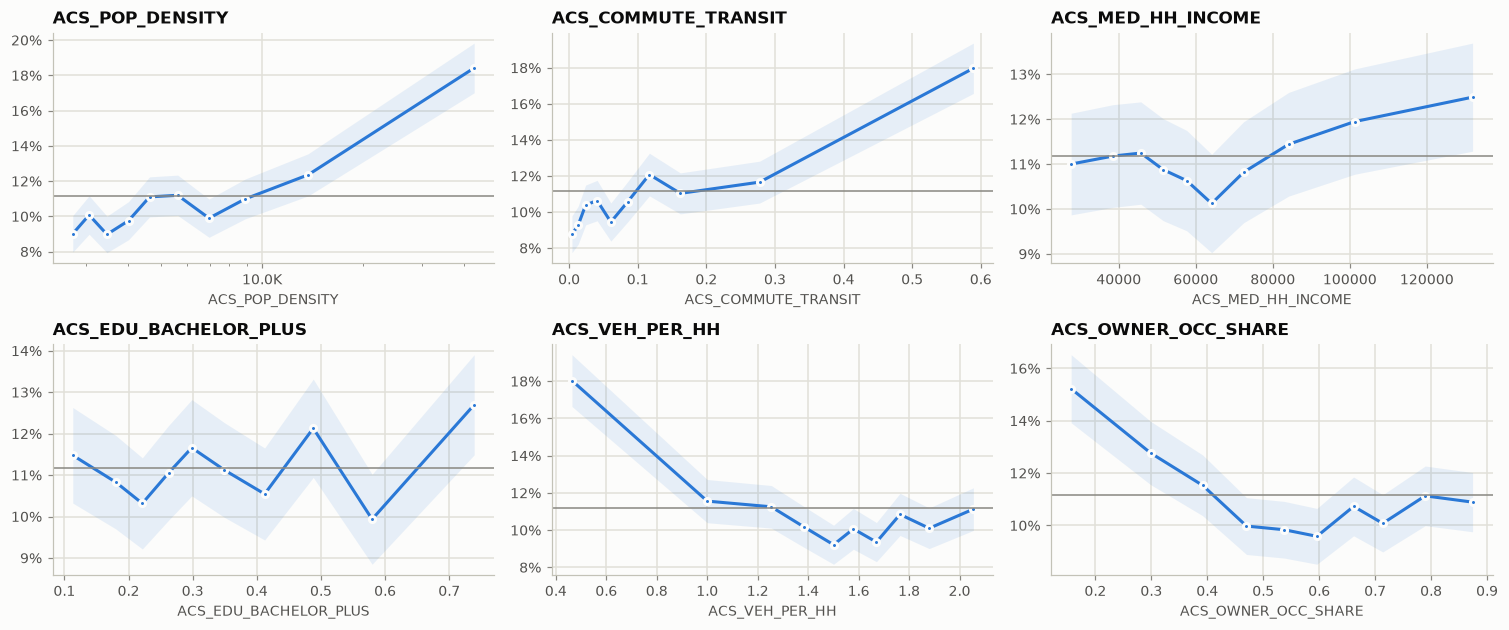

In [9]:
ACS = [c for c in FEATS if c.startswith('ACS_') and c != 'ACS_ZIP3_FILLED']
def within(c):  # AUC inside each state, averaged weighted by quote count
    p = [(len(g), auc_dir(g.CONVERT_IND, g[c])) for _, g in lab.groupby('STATE_CD', observed=True)]
    return np.average([a for _, a in p], weights=[n for n, _ in p])
acs_tbl = pd.DataFrame({'overall AUC': [auc1(lab[c]) for c in ACS], 'within-state AUC': [within(c) for c in ACS]}, index=ACS).round(3)
display(acs_tbl.sort_values('overall AUC', ascending=False).T)

fig, ax = grid(6)
for a, c in zip(ax, ['ACS_POP_DENSITY', 'ACS_COMMUTE_TRANSIT', 'ACS_MED_HH_INCOME', 'ACS_EDU_BACHELOR_PLUS', 'ACS_VEH_PER_HH', 'ACS_OWNER_OCC_SHARE']):
    rate_curve(a, lab[c], c)
logx(ax[0])
save(fig, '08_census')
pd.crosstab(lab.STATE_CD, pd.qcut(lab.ACS_POP_DENSITY, 4, labels=['sparse', 'Q2', 'Q3', 'dense']), normalize='index').round(2)

**Findings**
- **Urban ZIPs convert more:**
  - Signs of urban areas (high density, transit commuting, fewer vehicles per household, more renters) all go with higher conversion.
  - The densest decile converts at ~18% vs ~9% in the sparsest.
- **This isn't just a proxy for state:** density keeps a within-state AUC of 0.544 (0.557 overall) and transit share 0.537. Most Census features keep most of their signal inside a state; only the commute-time features fade (0.546 → 0.518).
- **Weak:** income, education and median age (AUC ≈ 0.50–0.52).
- The urban features largely measure the same thing (see §10), so one or two of them capture most of the value.

## 9. Missing values vs. conversion
`*_MISSING` flags mark numeric gaps, and categorical gaps are a `"Missing"` level. Is missingness itself predictive?

In [10]:
flags = {c.removesuffix('_MISSING'): lab[c].astype(bool) for c in lab if c.endswith('_MISSING')}
flags |= {'PRIOR_CARRIER_GRP': lab.PRIOR_CARRIER_GRP.eq('Missing'), 'COV_PKG_TYPE': lab.COV_PKG_TYPE.eq('Missing')}
pd.DataFrame({c: {'n missing': m.sum(), 'rate if missing': y[m].mean(), 'rate if present': y[~m].mean()} for c, m in flags.items()}).T.round(3)

,n missing,rate if missing,rate if present
QUOTED_AMT,64.0,0.047,0.112
CREDIT_SCORE,186.0,0.124,0.112
CAT_ZONE,150.0,0.100,0.112
ZIP_CD,281.0,0.110,0.112
PRIOR_CARRIER_GRP,2988.0,0.103,0.113
COV_PKG_TYPE,475.0,0.101,0.112


**Findings**
- Only a missing `QUOTED_AMT` stands out: 4.7% vs 11.2%. With n = 64 it's a small effect.
- Other gaps convert within noise of the average.
- The missing-value flags are harmless but carry little signal.

## 10. Redundancy: correlated features
Spearman correlations among numeric features. Highly correlated pairs (|ρ| > 0.8) carry the same information, which makes importance scores and SHAP harder to interpret. Gradient boosting doesn't strictly need them removed.

ρ
DRV_YOUNG_SHARE      DRV_DEPENDENT_SHARE   0.999
ACS_COMMUTE_MEAN_MIN ACS_COMMUTE_45PLUS    0.978
DRV_TELEMATICS_ANY   DRV_TELEMATICS_SHARE  0.932
DRV_SAFETY_MIN       DRV_SAFETY_MEAN       0.889
ACS_VEH_PER_HH       ACS_NO_VEH_SHARE     -0.869
DRV_COMMUTE_SUM      DRV_COMMUTE_MAX       0.858
DRV_AGE_MIN          DRV_AGE_MEAN          0.858
                     DRV_YOUNG_SHARE      -0.838
                     DRV_DEPENDENT_SHARE  -0.838
ACS_OWNER_OCC_SHARE  ACS_VEH_PER_HH        0.833
VEH_N_ROWS           VEH_MILEAGE_SUM       0.824
DRV_OWN_SHARE        DRV_RENT_SHARE       -0.814
DRV_AGE_MEAN         DRV_DEPENDENT_SHARE  -0.812
                     DRV_YOUNG_SHARE      -0.811
DISCOUNT_IND         HOME_POLICY_IND       0.804

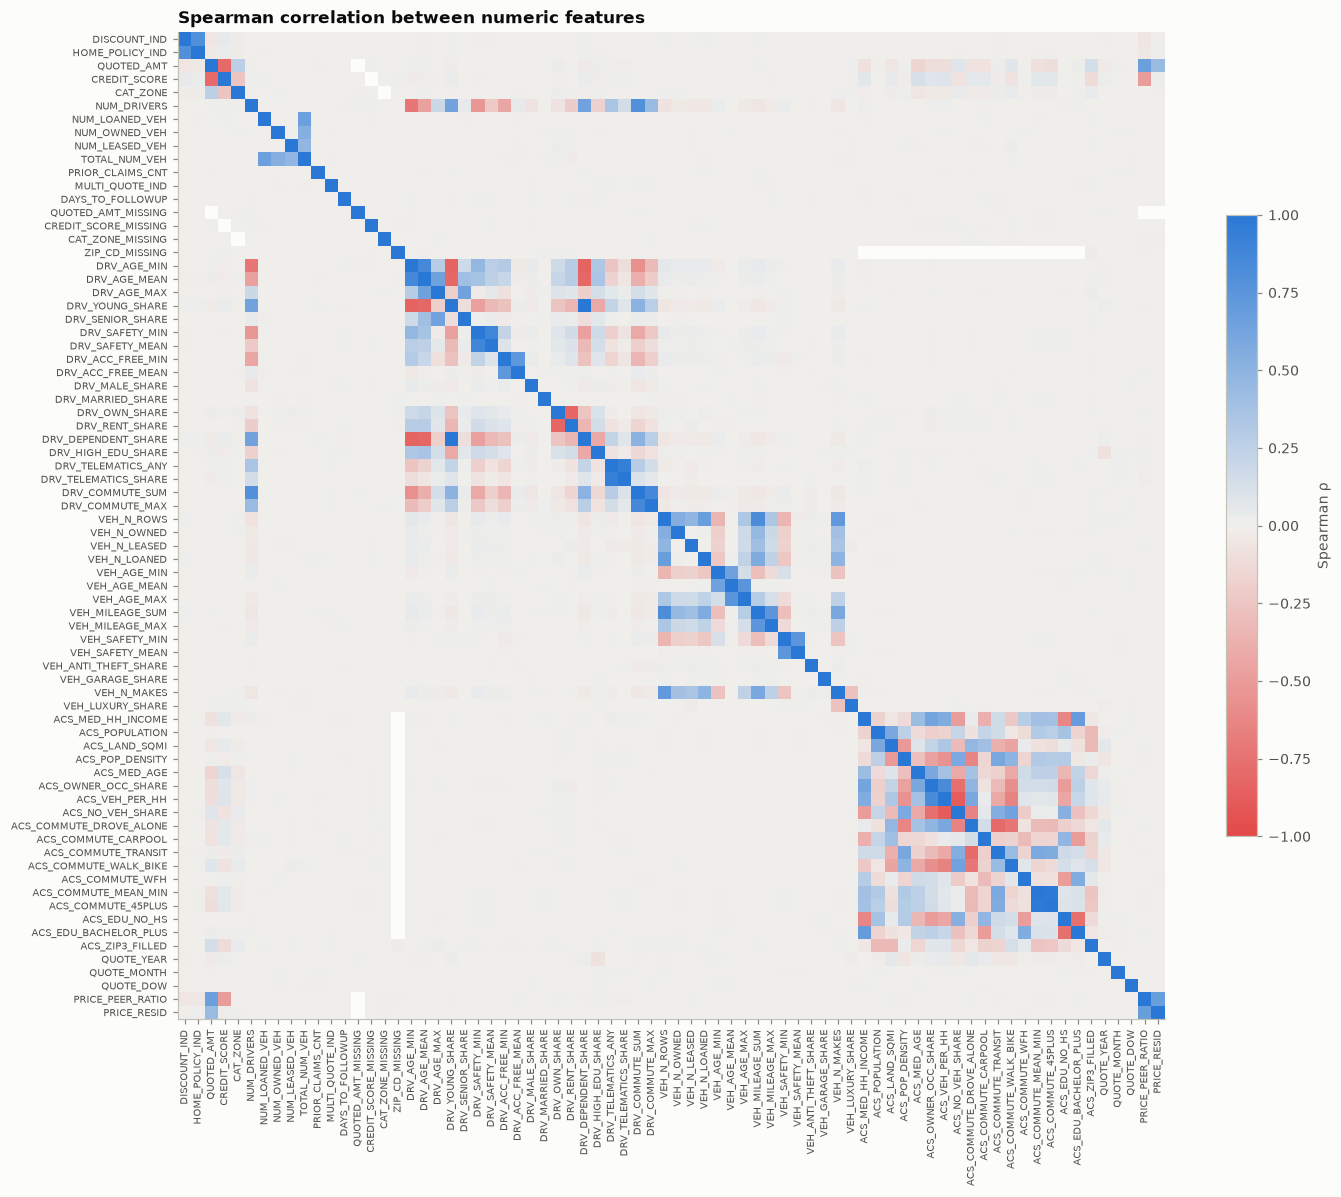

In [11]:
num = lab[FEATS + ['PRICE_PEER_RATIO', 'PRICE_RESID']].select_dtypes('number')
num = num.loc[:, num.nunique() > 1]
rho = num.corr('spearman')
fig, ax = plt.subplots(figsize=(13, 11))
im = ax.imshow(rho, cmap=DIVERGE, vmin=-1, vmax=1); ax.grid(False)
ax.set_xticks(range(len(rho)), rho.columns, rotation=90, fontsize=6.5); ax.set_yticks(range(len(rho)), rho.columns, fontsize=6.5)
fig.colorbar(im, ax=ax, shrink=.6, label='Spearman ρ'); ax.set_title('Spearman correlation between numeric features')
save(fig, '10_correlation')
pairs = rho.where(np.triu(np.ones(rho.shape, bool), 1)).stack()
pairs[pairs.abs() > .8].sort_values(key=abs, ascending=False).round(3).to_frame('ρ')

**Findings**
- `DRV_YOUNG_SHARE` ≈ `DRV_DEPENDENT_SHARE` (ρ = 0.999): in this data, "dependent" drivers *are* the under-25 drivers. Keep one.
- Other near-duplicates:
  - commute mean ↔ 45+ share: 0.98
  - telematics any ↔ share: 0.93
  - min/mean pairs for safety, age and commute: 0.86–0.89
- `DISCOUNT_IND` ↔ `HOME_POLICY_IND` (0.80) reflects the bundle structure from §7.
- **Candidates to drop for cleaner importance / SHAP:** `DRV_DEPENDENT_SHARE`, `ACS_COMMUTE_45PLUS`, `DRV_TELEMATICS_SHARE`.

## 11. Call-note text: why quotes didn't bind
Notes exist for **training quotes only** (~69% of them), so they're never model inputs. They follow a fixed template, *"Why quote: … Why not bound: …"*:
- One of ~25 "why quote" phrases, grouped here into 5 **shopping motives**.
- One or more "why not bound" phrases, tagged here as 9 **objections** by keyword. A note can have several.

**Checks:**
- Whether each objection lines up with the structured column it describes, e.g. *lienholder* ↔ loaned vehicles, *lease* ↔ leased vehicles, *CAT* ↔ CAT zone. If it does, the notes are just a text version of existing features.
- Whether converters' notes differ from non-converters' notes.

notes: 15,184 | conversion among noted quotes: 12.4% vs 9.8% un-noted labeled quotes
52% of notes quote a $ amount; it equals QUOTED_AMT in 100.0% of them


,condition,cited | condition true,cited | condition false
lienholder,any loaned veh,0.202254,0.0
lease terms,any leased veh,0.190688,0.0
home bundle,no home policy,0.220105,0.273158
no discount,no discount,0.237023,0.060349
low pkg too thin,Low pkg,0.207721,0.0
high pkg too much,High pkg,0.163908,0.0
CAT / storm,CAT zone 4–5,0.176768,0.0
other drivers,2+ drivers,0.097725,0.0


PRIOR_CARRIER_GRP,carrier known,carrier missing
MOTIVE,,
no prior carrier,0.000,0.74
non-renewed / moved,0.112,0.00
routine shopping,0.498,0.26
service / claims,0.112,0.00
unhappy with price,0.277,0.00


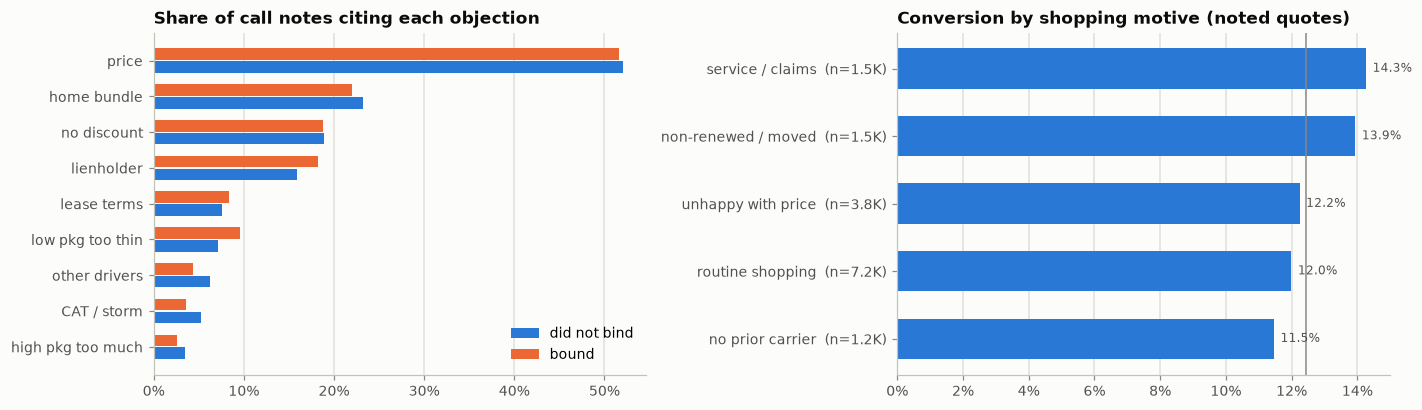

In [12]:
t = notes.merge(lab.drop(columns='CONVERT_IND'), on='POLICY_ID')
parts = t.CALL_NOTE.str.extract(r'Why quote:\s*(?P<why>.*?)\s*Why not bound:\s*(?P<obj>.*)$')
MOTIVES = {'no prior carrier': r'no carrier|no existing|first policy|first time|starting fresh|no current carrier',
           'unhappy with price': r'expensive|pricing|jumped|raised rates|loyalty discount',
           'service / claims': r'service|claims handling', 'non-renewed / moved': r'non-renewed|moved',
           'routine shopping': r'.'}  # fallback: annual review, comparing, shopping around…
OBJECTIONS = {'price': r'\$[\d,]+', 'no discount': r'discount', 'home bundle': r'bundl|home policy', 'lienholder': r'lienholder',
              'lease terms': r'leas|lessor', 'low pkg too thin': r'low package', 'high pkg too much': r'more than they need|leaner|high package',
              'CAT / storm': r'CAT|storm', 'other drivers': r'drivers'}
t['MOTIVE'] = parts.why.apply(lambda s: next(m for m, p in MOTIVES.items() if re.search(p, s)))
for o, p in OBJECTIONS.items(): t[o] = parts.obj.str.contains(p)
t['NOTE_AMT'] = parts.obj.str.extract(r'\$([\d,]+)', expand=False).str.replace(',', '').astype(float)
print(f'notes: {len(t):,} | conversion among noted quotes: {t.CONVERT_IND.mean():.1%} vs {y[~lab.POLICY_ID.isin(notes.POLICY_ID)].mean():.1%} un-noted labeled quotes')
has_amt = t.NOTE_AMT.notna()
print(f'{has_amt.mean():.0%} of notes quote a $ amount; it equals QUOTED_AMT in {(t.NOTE_AMT[has_amt] == t.QUOTED_AMT[has_amt]).mean():.1%} of them')

freq = t.groupby('CONVERT_IND')[list(OBJECTIONS)].mean().T.rename(columns={0.0: 'did not bind', 1.0: 'bound'}).sort_values('did not bind')
fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 3.8))
pos, h = np.arange(len(freq)), .36
for i, col in enumerate(freq):
    a1.barh(pos + (i - .5) * h, freq[col], height=h * .9, color=SERIES[i], label=col)
a1.set_yticks(pos, freq.index); a1.xaxis.set_major_formatter(pct); a1.legend(loc='lower right'); a1.grid(axis='y', visible=False)
a1.set_title('Share of call notes citing each objection')
r = t.groupby('MOTIVE').CONVERT_IND.agg(['mean', 'size']).sort_values('mean'); p2 = np.arange(len(r))
a2.barh(p2, r['mean'], height=.6, color=SERIES[0]); a2.set_yticks(p2, [f'{i}  (n={k(n)})' for i, n in zip(r.index, r['size'])])
a2.axvline(t.CONVERT_IND.mean(), color=MUTED, lw=1); a2.xaxis.set_major_formatter(pct); a2.grid(axis='y', visible=False)
for p, v in zip(p2, r['mean']): a2.text(v + .002, p, f'{v:.1%}', va='center', color=INK2, fontsize=8)
a2.set_title('Conversion by shopping motive (noted quotes)')
save(fig, '11_call_notes')

# Does each objection mirror a structured column? Share citing the objection, split by that column
CHECKS = {'lienholder': t.NUM_LOANED_VEH > 0, 'lease terms': t.NUM_LEASED_VEH > 0, 'home bundle': t.HOME_POLICY_IND == 0,
          'no discount': t.DISCOUNT_IND == 0, 'low pkg too thin': t.COV_PKG_TYPE == 'Low', 'high pkg too much': t.COV_PKG_TYPE == 'High',
          'CAT / storm': t.CAT_ZONE >= 4, 'other drivers': t.NUM_DRIVERS > 1}
display(pd.DataFrame({o: {'condition': c, 'cited | condition true': t[o][m].mean(), 'cited | condition false': t[o][~m].mean()}
              for (o, m), c in zip(CHECKS.items(), ['any loaned veh', 'any leased veh', 'no home policy', 'no discount', 'Low pkg', 'High pkg', 'CAT zone 4–5', '2+ drivers'])}).T.round(3))
display(pd.crosstab(t.MOTIVE, t.PRIOR_CARRIER_GRP.eq('Missing').map({True: 'carrier missing', False: 'carrier known'}), normalize='columns').round(3))

**Findings**
- **The objections are generated from structured columns.**
  - Each objection appears **only** when its condition holds: *lienholder* only with a loaned vehicle, *lease* only with a leased vehicle, *low/high package* only with that package, *CAT* only in zones 4–5, *other drivers* only with 2+ drivers.
  - Home bundle comes in two versions: "explore a bundle" (no home policy) and "compare with my current home carrier" (has one).
  - Every dollar amount in a note equals `QUOTED_AMT`.
  - **So the notes add nothing beyond existing columns, and dropping them loses no information.**
- **"Why not bound" is not a reliable lost-reason:** bound quotes have notes too, with nearly the same mix of objections. Read the notes as hesitations raised during the call, not final outcomes.
- **For the presentation:** price is the most-cited objection (**~52% of notes**), followed by home bundle (~23%) and missing discount (~19%). This matches the price, discount and bundle effects above.
- **Shopping motive:**
  - Customers switching because of poor **service/claims** or a **non-renewal** convert best (~14%). Motivated switchers are easier to win.
  - "No prior carrier" lines up with a missing `PRIOR_CARRIER_GRP` (74% of those quotes).

## 12. Overall signal ranking + quick LightGBM check
- **Single-feature AUC** (direction-free) and **within-state AUC** for every numeric feature.
- A **default LightGBM** with 5-fold stratified CV on the labeled rows. This isn't the final model: it sets a reference AUC / top-decile precision and shows which features it uses.
- The model is run with and without the two price-competitiveness features from section 6, to see whether they add signal.

,AUC,within-state AUC
QUOTED_AMT,0.571,0.564
CAT_ZONE,0.569,0.565
CREDIT_SCORE,0.565,0.553
DRV_HIGH_EDU_SHARE,0.563,0.564
DRV_YOUNG_SHARE,0.559,0.560
DRV_DEPENDENT_SHARE,0.559,0.560
ACS_POP_DENSITY,0.557,0.544
ACS_COMMUTE_TRANSIT,0.556,0.537
ACS_COMMUTE_DROVE_ALONE,0.547,0.539
ACS_COMMUTE_MEAN_MIN,0.546,0.518


,base features,+ price competitiveness
CV AUC,0.6904,0.6888
top-decile precision,0.2746,0.2732


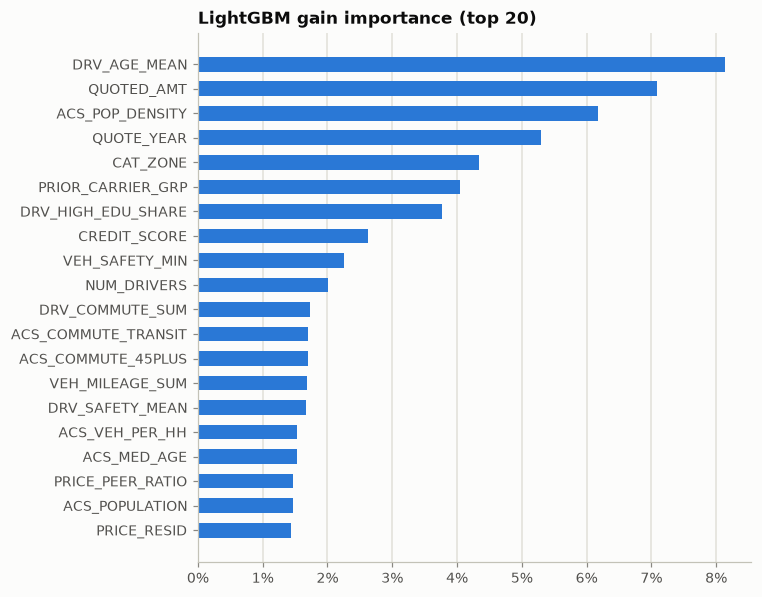

In [13]:
rank = pd.DataFrame({c: {'AUC': auc1(lab[c]), 'within-state AUC': within(c)} for c in num.columns if lab[c].notna().sum() > 1000}).T
display(rank.sort_values('AUC', ascending=False).head(25).round(3))

def cv_lgb(cols, seed=0):
    oof = cross_val_predict(lgb.LGBMClassifier(n_estimators=300, learning_rate=.03, num_leaves=15, min_child_samples=50,
                            subsample=.8, subsample_freq=1, colsample_bytree=.8, verbose=-1, random_state=seed),
                            lab[cols], y, cv=StratifiedKFold(5, shuffle=True, random_state=seed), method='predict_proba')[:, 1]
    top = oof >= np.quantile(oof, .9)
    return roc_auc_score(y, oof), y[top].mean(), oof

res = {name: cv_lgb(cols)[:2] for name, cols in [('base features', FEATS), ('+ price competitiveness', FEATS + ['PRICE_PEER_RATIO', 'PRICE_RESID'])]}
display(pd.DataFrame(res, index=['CV AUC', 'top-decile precision']).round(4))

model = lgb.LGBMClassifier(n_estimators=300, learning_rate=.03, num_leaves=15, min_child_samples=50, subsample=.8, subsample_freq=1,
                           colsample_bytree=.8, verbose=-1).fit(lab[FEATS + ['PRICE_PEER_RATIO', 'PRICE_RESID']], y)
imp = pd.Series(model.booster_.feature_importance('gain'), model.booster_.feature_name()).pipe(lambda s: s / s.sum()).nlargest(20)[::-1]
fig, ax = plt.subplots(figsize=(7, 5.5))
ax.barh(range(len(imp)), imp, height=.6, color=SERIES[0]); ax.set_yticks(range(len(imp)), imp.index)
ax.xaxis.set_major_formatter(pct); ax.grid(axis='y', visible=False); ax.set_title('LightGBM gain importance (top 20)')
save(fig, '12_importance')

**Findings**
- **No single feature dominates:** the best single-feature AUC is 0.571, so the signal is spread across many features. That's typical where gradient boosting beats simple scorecards.
- **Default LightGBM: CV AUC 0.690, top-decile precision 27.5%** (2.5× the 11.2% base rate). This is the reference to beat.
- **Price-competitiveness features add nothing:** 0.689 with them vs 0.690 without, so leave them out.
- **Top features by gain:**
  1. average driver age
  2. quoted amount
  3. **population density (Census)**: the external data earns its place
  4. quote year
  5. CAT zone
  6. prior carrier
  7. high-education share
  8. credit score

## 13. Key takeaways

**What drives conversion**
1. **The household:**
   - credit score: ~7% → ~15% across its range
   - average driver age 35–50: ~16% vs 7–10%
   - fewer drivers: 12% for 1–2 vs 4% for 6
   - higher education
2. **Price:**
   - The cheapest decile converts **~2.7×** better than the most expensive.
   - What counts is the absolute price, not price relative to risk.
   - Low-credit customers are the most price-sensitive.
3. **Product and risk:** Low coverage packages and low CAT zones convert more, and the two effects add up (16% vs 7%). Discounts add about +3 pp, and the bundle always comes with a discount.
4. **Location:** NY/NJ (~13%) far outperform GA/WI/AL (5–7%), and dense urban ZIPs convert ~2× rural ones even within a state.
5. **Prior carrier:** customers leaving Carrier_8 or Carrier_3 convert at about twice the rate of those leaving Carrier_7.

**What doesn't (contrary to the brief's hypotheses):** quote channel, multi-carrier shopping, days to follow-up, prior claims and vehicle characteristics are all flat within noise, alone and in combination with each other.

**For modeling**
- Use stratified 5-fold CV on train + valid; holdout looks the same (adversarial AUC 0.50).
- The baseline to beat is **0.690 AUC / 27.5% top-decile precision**.
- Effects are non-monotone (driver age), stack up (package × CAT zone) and are concentrated in segments (credit × price), which favors tree ensembles.
- Keep raw price and skip the price-relative features. Consider dropping the near-duplicates from §10.
- **Next features to test:**
  - target encoding (in CV) of `PRIOR_CARRIER_GRP`, `ZIP3` and `MAKE_MODEL`
  - prior carrier × state
  - driver-age bands
  - credit × price
- `CALL_NOTE` is confirmed safe to drop: it's generated from existing columns.

**Starting points for the business recommendations**
- **Rank the follow-up queue by model score:** the top decile converts at ~2.5× the base rate.
- **Target discounts** at low-credit customers with high quotes; that's where price moves conversion.
- **Promote discounts and the home bundle,** both clearly linked to higher conversion.
- **Don't count on faster follow-up or channel shifts alone;** the data shows no effect from either.